<a href="https://colab.research.google.com/github/318281029SBH/Escuela/blob/main/HotelAffluence.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd

In [ ]:
import numpy as np

# Data preparing

In [ ]:
df=pd.read_csv('/content/drive/MyDrive/dataSet/hotel_booking_data.csv')

In [ ]:
df.nunique()

,0
hotel,2
is_canceled,2
lead_time,479
arrival_date_year,3
arrival_date_month,12
arrival_date_week_number,53
arrival_date_day_of_month,31
stays_in_weekend_nights,17
stays_in_week_nights,35
adults,14


In [ ]:
df.shape

(119390, 36)

In [ ]:
df.dtypes

,0
hotel,object
is_canceled,int64
lead_time,int64
arrival_date_year,int64
arrival_date_month,object
arrival_date_week_number,int64
arrival_date_day_of_month,int64
stays_in_weekend_nights,int64
stays_in_week_nights,int64
adults,int64


In [ ]:
data=df.pivot_table(index=['arrival_date_month','arrival_date_day_of_month','arrival_date_year','arrival_date_week_number','hotel'],values='is_canceled',aggfunc='count')
data.reset_index(inplace=True)
data.rename(columns={'is_canceled':'afluencia'},inplace=True)

In [ ]:
data['date_str'] = data['arrival_date_year'].astype(str) + '-' + data['arrival_date_month'].astype(str) + '-' + data['arrival_date_day_of_month'].astype(str)
data['arrival_date'] = pd.to_datetime(data['date_str'], errors='coerce')
data.sort_values('arrival_date',inplace=True)
data.reset_index(inplace=True,drop=True)
#display(data.head())

In [ ]:
data['afluencia'].describe(percentiles= np.arange(0,1.01,.1) )

,afluencia
count,793.000000
mean,150.554855
std,63.316045
min,19.000000
0%,19.000000
10%,69.000000
20%,96.000000
30%,115.600000
40%,131.000000
50%,147.000000


In [ ]:
data['afluencia'].describe().loc['50%']

np.float64(147.0)

In [ ]:
#data['y2'] = np.where( data['afluencia'] <= data['afluencia'].describe().loc['50%']   ,0 ,1 )

In [ ]:
#data['y2'].value_counts(1)*100

,proportion
y2,
0,50.315259
1,49.684741


In [ ]:
data_piv=data.copy()
#data=data[['afluencia','y2','hotel']]
#data['timestamp']=np.arange(1,len(data)+1)

<Axes: >

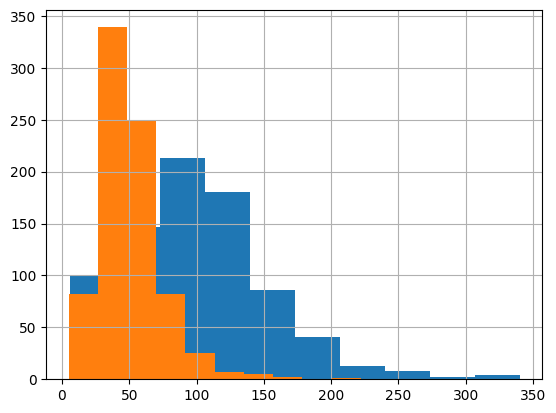

In [ ]:
data_piv.loc[data_piv['hotel']=='City Hotel']['afluencia'].hist()
data_piv.loc[data_piv['hotel']=='Resort Hotel']['afluencia'].hist()

In [ ]:
df_city=data_piv.loc[data_piv['hotel']=='City Hotel']
df_res=data_piv.loc[data_piv['hotel']=='Resort Hotel']

In [ ]:
df_city['timestamp']=np.arange(1,len(df_city)+1)
df_res['timestamp']=np.arange(1,len(df_res)+1)

/tmp/ipython-input-2754746063.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_city['timestamp']=np.arange(1,len(df_city)+1)
/tmp/ipython-input-2754746063.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_res['timestamp']=np.arange(1,len(df_res)+1)


In [ ]:
df_res.shape, df_city.shape

((793, 10), (793, 10))

In [ ]:
df_hotel=pd.concat([df_city,df_res],axis=0,ignore_index=True).sort_values('timestamp')

In [ ]:
data=df_hotel[['afluencia','timestamp','hotel']].reset_index(drop=True)

In [ ]:
data

,afluencia,timestamp,hotel
0,79,1,City Hotel
1,43,1,Resort Hotel
2,44,2,Resort Hotel
3,49,2,City Hotel
4,16,3,City Hotel
...,...,...,...
1581,35,791,Resort Hotel
1582,42,792,Resort Hotel
1583,47,792,City Hotel
1584,55,793,Resort Hotel


# agreggating functions

In [ ]:
def sum_inc(l):
    return sum( [ int(y>x) for x,y in zip(l , l[1:] ) ] )

def sum_dec(l):
    return sum( [ int(y<x) for x,y in zip(l , l[1:] ) ] )

def media_inc(l):
    return np.mean( [ int(y>x) for x,y in zip(l , l[1:] ) ] )

def media_dec(l):
    return np.mean( [ int(y<x) for x,y in zip(l , l[1:] ) ] )

def delta_min(l):
    try:
        return min( [ float( y-x ) for x,y in zip(l , l[1:] ) ]  )
    except:
        return np.nan

def delta_max(l):
    try:
        return  max( [ float( y-x ) for x,y in zip(l , l[1:] ) ]  )
    except:
        return np.nan

def delta_mean(l):
    try:
        return  np.mean( [ float( y-x ) for x,y in zip(l , l[1:] ) ]  )
    except:
        return np.nan

def delta_desv(l):
    try:
        return  np.std( [ float( y-x ) for x,y in zip(l , l[1:] ) ]  )
    except:
        return np.nan

def pct_delta_min(l):
    try:
        return  min( [ float( (y-x)/x ) for x,y in zip(l , l[1:] ) ]  )
    except:
        return np.nan

def pct_delta_max(l):
    try:
        return  max( [ float( (y-x)/x ) for x,y in zip(l , l[1:] ) ]  )
    except:
        return np.nan

def pct_delta_mean(l):
    try:
        return  np.mean( [ float( (y-x)/x ) for x,y in zip(l , l[1:] ) ]  )
    except:
        return np.nan

def pct_delta_desv(l):
    try:
        return  np.std( [ float( (y-x)/x ) for x,y in zip(l , l[1:] ) ]  )
    except:
        return np.nan

def max_racha_inc(l):
    return max( [ len(i) for i in "".join([ str( int(y>x)  ) for x,y in zip(l,l[1:])  ]).split('0')  ]   )

def max_racha_dec(l):
    return max( [ len(i) for i in "".join([ str( int(y<x)  ) for x,y in zip(l,l[1:])  ]).split('0')  ]   )

def media_racha_inc(l):
    return np.mean( [ len(i) for i in "".join([ str( int(y>x)  ) for x,y in zip(l,l[1:])  ]).split('0')  ]   )

def media_racha_dec(l):
    return np.mean( [ len(i) for i in "".join([ str( int(y<x)  ) for x,y in zip(l,l[1:])  ]).split('0')  ]   )

In [ ]:
lst_func = [ 'sum','min','mean','max','std',
            sum_inc , sum_dec ,  media_inc, media_dec,
            delta_min, delta_max, delta_mean, delta_desv,
            pct_delta_min, pct_delta_max, pct_delta_mean, pct_delta_desv,
            max_racha_inc, max_racha_dec, media_racha_inc, media_racha_dec ]

# Ventanas

In [ ]:
#um = ['id_estacion']

t_min = data['timestamp'].min()
t_max = data['timestamp'].max()



In [ ]:
data.shape

(793, 3)

In [ ]:
um=['hotel']

In [ ]:
vdes = 1
vobs = 30

anclai = t_min + vobs -1
anclaf = t_max - vdes

In [ ]:
print("Ventanas: ", vdes , " --- ", vobs)
print("Anclas: ", anclai , " --- ", anclaf)

Ventanas:  1  ---  30
Anclas:  30  ---  792


In [ ]:
%%time
lst_aux = []

for ancla in range(anclai, anclaf + 1):

    print("Intervalo: ",ancla - anclai, ancla , " Para pronosticar: ", ancla+vdes)

    aux = data[ ( data['timestamp']>  ancla - anclai ) &
              ( data['timestamp']<= ancla )  ].reset_index(drop=True)

    aux = aux.pivot_table( index = um ,
                           values = 'afluencia',
                           aggfunc = lst_func )

    aux.columns = [ f'v_{i}_{j}' for i,j in aux.columns ]

    aux.insert( 0 , 'ancla' , ancla )

    aux.reset_index(inplace=True)

    lst_aux.append(aux)

Intervalo:  0 30  Para pronosticar:  31
Intervalo:  1 31  Para pronosticar:  32
Intervalo:  2 32  Para pronosticar:  33
Intervalo:  3 33  Para pronosticar:  34
Intervalo:  4 34  Para pronosticar:  35
Intervalo:  5 35  Para pronosticar:  36
Intervalo:  6 36  Para pronosticar:  37
Intervalo:  7 37  Para pronosticar:  38
Intervalo:  8 38  Para pronosticar:  39
Intervalo:  9 39  Para pronosticar:  40
Intervalo:  10 40  Para pronosticar:  41
Intervalo:  11 41  Para pronosticar:  42
Intervalo:  12 42  Para pronosticar:  43
Intervalo:  13 43  Para pronosticar:  44
Intervalo:  14 44  Para pronosticar:  45
Intervalo:  15 45  Para pronosticar:  46
Intervalo:  16 46  Para pronosticar:  47
Intervalo:  17 47  Para pronosticar:  48
Intervalo:  18 48  Para pronosticar:  49
Intervalo:  19 49  Para pronosticar:  50
Intervalo:  20 50  Para pronosticar:  51
Intervalo:  21 51  Para pronosticar:  52
Intervalo:  22 52  Para pronosticar:  53
Intervalo:  23 53  Para pronosticar:  54
Intervalo:  24 54  Para pr

In [ ]:
data[ ( data['timestamp']>  630 - anclai ) & ( data['timestamp']<= 630 )  ].reset_index(drop=True)

,afluencia,timestamp,hotel
0,58,601,Resort Hotel
1,116,601,City Hotel
2,57,602,City Hotel
3,49,602,Resort Hotel
4,72,603,Resort Hotel
5,98,603,City Hotel
6,101,604,City Hotel
7,69,604,Resort Hotel
8,95,605,City Hotel
9,57,605,Resort Hotel


In [ ]:
lst_aux[600]

,hotel,ancla,v_sum_afluencia,v_min_afluencia,v_mean_afluencia,v_max_afluencia,v_std_afluencia,v_sum_inc_afluencia,v_sum_dec_afluencia,v_media_inc_afluencia,...,v_delta_mean_afluencia,v_delta_desv_afluencia,v_pct_delta_min_afluencia,v_pct_delta_max_afluencia,v_pct_delta_mean_afluencia,v_pct_delta_desv_afluencia,v_max_racha_inc_afluencia,v_max_racha_dec_afluencia,v_media_racha_inc_afluencia,v_media_racha_dec_afluencia
0,City Hotel,630,3326,42,110.866667,230,41.921711,14,15,0.482759,...,0.344828,58.439639,-0.580000,2.239437,0.144755,0.628263,3,3,0.875,1.0
1,Resort Hotel,630,1639,23,54.633333,109,24.016493,14,15,0.482759,...,-1.034483,35.970757,-0.761905,3.038462,0.196593,0.829169,3,3,0.875,1.0


In [ ]:
X = pd.concat( lst_aux  , ignore_index=True)

In [ ]:
X

,hotel,ancla,v_sum_afluencia,v_min_afluencia,v_mean_afluencia,v_max_afluencia,v_std_afluencia,v_sum_inc_afluencia,v_sum_dec_afluencia,v_media_inc_afluencia,...,v_delta_mean_afluencia,v_delta_desv_afluencia,v_pct_delta_min_afluencia,v_pct_delta_max_afluencia,v_pct_delta_mean_afluencia,v_pct_delta_desv_afluencia,v_max_racha_inc_afluencia,v_max_racha_dec_afluencia,v_media_racha_inc_afluencia,v_media_racha_dec_afluencia
0,City Hotel,30,1389,6,46.300000,149,37.950194,16,13,0.551724,...,-0.965517,59.267647,-0.959732,20.285714,2.073837,5.023006,4,2,1.142857,0.764706
1,Resort Hotel,30,1318,24,43.933333,66,10.944794,15,13,0.517241,...,0.172414,15.288195,-0.612903,1.068966,0.065431,0.357043,2,2,1.000000,0.764706
2,City Hotel,31,1319,6,43.966667,149,38.022211,16,13,0.551724,...,-1.379310,59.510308,-0.959732,20.285714,2.058534,5.031127,4,2,1.142857,0.764706
3,Resort Hotel,31,1335,24,44.500000,66,11.328177,15,13,0.517241,...,0.551724,15.439730,-0.612903,1.068966,0.073250,0.358513,3,2,1.000000,0.764706
4,City Hotel,32,1305,6,43.500000,149,38.044212,17,12,0.586207,...,0.655172,59.402935,-0.959732,20.285714,2.181374,5.006351,4,2,1.307692,0.666667
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1521,Resort Hotel,790,1784,32,59.466667,89,13.315102,21,8,0.724138,...,0.862069,16.083241,-0.428571,0.648148,0.050083,0.267110,5,2,2.333333,0.363636
1522,City Hotel,791,3118,60,103.933333,139,19.321122,15,14,0.517241,...,-1.000000,26.799382,-0.361702,0.666667,0.025840,0.277794,3,3,1.000000,0.875000
1523,Resort Hotel,791,1766,32,58.866667,89,14.004269,20,9,0.689655,...,-0.965517,17.854745,-0.551282,0.648148,0.024568,0.287236,5,2,2.000000,0.428571
1524,City Hotel,792,3046,47,101.533333,139,21.709260,15,14,0.517241,...,-1.965517,27.773074,-0.477778,0.666667,0.013712,0.291501,3,3,1.000000,0.875000


In [ ]:
%%time
lst_aux2 = []

for ancla in range(anclai, anclaf +1):

    print("Intervalo: ", ancla - anclai , ancla , " Para pronosticar: ",ancla+vdes)

    aux = data[ (data['timestamp'] > ancla-anclai) & (data['timestamp'] <= ancla + vdes ) ].reset_index(drop=True)
    aux =  aux.pivot_table( index= um , columns='timestamp', values='afluencia')

    aux['y'] = aux[ ancla + vdes ]

    aux = aux[['y']]

    aux.insert( 0 , 'ancla', ancla)

    aux.reset_index(inplace=True)

    lst_aux2.append(aux)

Intervalo:  0 30  Para pronosticar:  31
Intervalo:  1 31  Para pronosticar:  32
Intervalo:  2 32  Para pronosticar:  33
Intervalo:  3 33  Para pronosticar:  34
Intervalo:  4 34  Para pronosticar:  35
Intervalo:  5 35  Para pronosticar:  36
Intervalo:  6 36  Para pronosticar:  37
Intervalo:  7 37  Para pronosticar:  38
Intervalo:  8 38  Para pronosticar:  39
Intervalo:  9 39  Para pronosticar:  40
Intervalo:  10 40  Para pronosticar:  41
Intervalo:  11 41  Para pronosticar:  42
Intervalo:  12 42  Para pronosticar:  43
Intervalo:  13 43  Para pronosticar:  44
Intervalo:  14 44  Para pronosticar:  45
Intervalo:  15 45  Para pronosticar:  46
Intervalo:  16 46  Para pronosticar:  47
Intervalo:  17 47  Para pronosticar:  48
Intervalo:  18 48  Para pronosticar:  49
Intervalo:  19 49  Para pronosticar:  50
Intervalo:  20 50  Para pronosticar:  51
Intervalo:  21 51  Para pronosticar:  52
Intervalo:  22 52  Para pronosticar:  53
Intervalo:  23 53  Para pronosticar:  54
Intervalo:  24 54  Para pr

In [ ]:
y = pd.concat( lst_aux2  , ignore_index=True)

In [ ]:
X

,hotel,ancla,v_sum_afluencia,v_min_afluencia,v_mean_afluencia,v_max_afluencia,v_std_afluencia,v_sum_inc_afluencia,v_sum_dec_afluencia,v_media_inc_afluencia,...,v_delta_mean_afluencia,v_delta_desv_afluencia,v_pct_delta_min_afluencia,v_pct_delta_max_afluencia,v_pct_delta_mean_afluencia,v_pct_delta_desv_afluencia,v_max_racha_inc_afluencia,v_max_racha_dec_afluencia,v_media_racha_inc_afluencia,v_media_racha_dec_afluencia
0,City Hotel,30,1389,6,46.300000,149,37.950194,16,13,0.551724,...,-0.965517,59.267647,-0.959732,20.285714,2.073837,5.023006,4,2,1.142857,0.764706
1,Resort Hotel,30,1318,24,43.933333,66,10.944794,15,13,0.517241,...,0.172414,15.288195,-0.612903,1.068966,0.065431,0.357043,2,2,1.000000,0.764706
2,City Hotel,31,1319,6,43.966667,149,38.022211,16,13,0.551724,...,-1.379310,59.510308,-0.959732,20.285714,2.058534,5.031127,4,2,1.142857,0.764706
3,Resort Hotel,31,1335,24,44.500000,66,11.328177,15,13,0.517241,...,0.551724,15.439730,-0.612903,1.068966,0.073250,0.358513,3,2,1.000000,0.764706
4,City Hotel,32,1305,6,43.500000,149,38.044212,17,12,0.586207,...,0.655172,59.402935,-0.959732,20.285714,2.181374,5.006351,4,2,1.307692,0.666667
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1521,Resort Hotel,790,1784,32,59.466667,89,13.315102,21,8,0.724138,...,0.862069,16.083241,-0.428571,0.648148,0.050083,0.267110,5,2,2.333333,0.363636
1522,City Hotel,791,3118,60,103.933333,139,19.321122,15,14,0.517241,...,-1.000000,26.799382,-0.361702,0.666667,0.025840,0.277794,3,3,1.000000,0.875000
1523,Resort Hotel,791,1766,32,58.866667,89,14.004269,20,9,0.689655,...,-0.965517,17.854745,-0.551282,0.648148,0.024568,0.287236,5,2,2.000000,0.428571
1524,City Hotel,792,3046,47,101.533333,139,21.709260,15,14,0.517241,...,-1.965517,27.773074,-0.477778,0.666667,0.013712,0.291501,3,3,1.000000,0.875000


In [ ]:
data.isna().sum()

,0
afluencia,0
timestamp,0
hotel,0


In [ ]:
tad = X.merge( y , on=['hotel','ancla'] , how='inner' )

In [ ]:
tad.columns

Index(['hotel', 'ancla', 'v_sum_afluencia', 'v_min_afluencia',
       'v_mean_afluencia', 'v_max_afluencia', 'v_std_afluencia',
       'v_sum_inc_afluencia', 'v_sum_dec_afluencia', 'v_media_inc_afluencia',
       'v_media_dec_afluencia', 'v_delta_min_afluencia',
       'v_delta_max_afluencia', 'v_delta_mean_afluencia',
       'v_delta_desv_afluencia', 'v_pct_delta_min_afluencia',
       'v_pct_delta_max_afluencia', 'v_pct_delta_mean_afluencia',
       'v_pct_delta_desv_afluencia', 'v_max_racha_inc_afluencia',
       'v_max_racha_dec_afluencia', 'v_media_racha_inc_afluencia',
       'v_media_racha_dec_afluencia', 'y'],
      dtype='object')

In [ ]:
import seaborn as sns

<Axes: xlabel='y', ylabel='Count'>

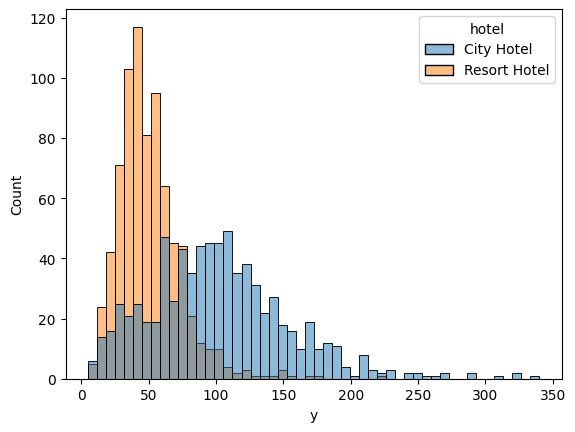

In [ ]:
sns.histplot(data=tad, x='y', bins=50, hue='hotel')

In [ ]:
# Use .drop() to remove the 'y' column from the index
features=np.array(tad.columns.drop(['y','ancla']))

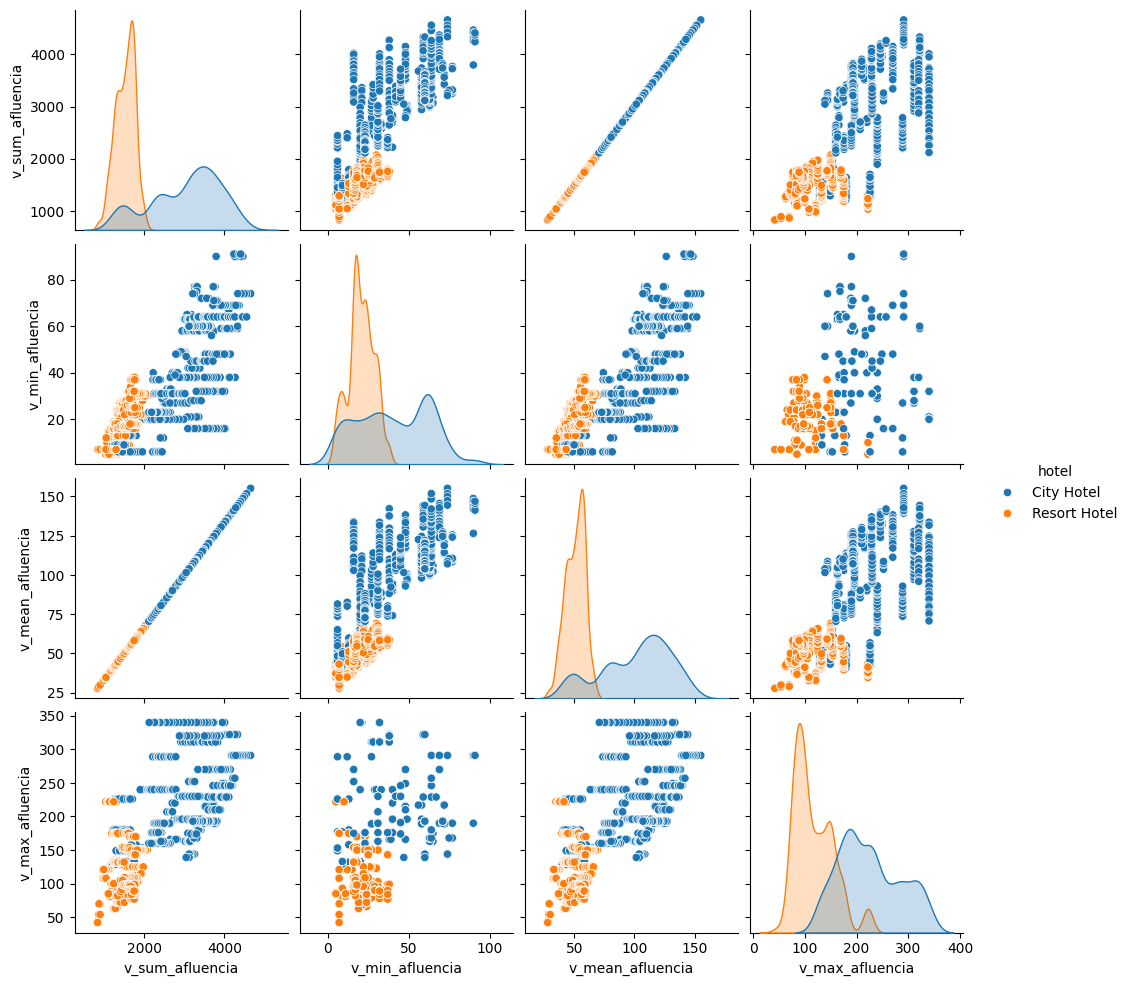

In [ ]:
sns.pairplot(tad[features[:5]],hue='hotel')

#EDA

##Continuas

In [ ]:
varc = [c for c in tad.columns.tolist() if c[:2]=='v_']

In [ ]:
varc

['v_sum_afluencia',
 'v_min_afluencia',
 'v_mean_afluencia',
 'v_max_afluencia',
 'v_std_afluencia',
 'v_sum_inc_afluencia',
 'v_sum_dec_afluencia',
 'v_media_inc_afluencia',
 'v_media_dec_afluencia',
 'v_delta_min_afluencia',
 'v_delta_max_afluencia',
 'v_delta_mean_afluencia',
 'v_delta_desv_afluencia',
 'v_pct_delta_min_afluencia',
 'v_pct_delta_max_afluencia',
 'v_pct_delta_mean_afluencia',
 'v_pct_delta_desv_afluencia',
 'v_max_racha_inc_afluencia',
 'v_max_racha_dec_afluencia',
 'v_media_racha_inc_afluencia',
 'v_media_racha_dec_afluencia']

###Análisis Univariado

### Missings

###VarianzaThershold

In [ ]:
vt = VarianceThreshold(threshold=1)

###Extremos

In [ ]:
tad2=tad.copy()

In [ ]:
ext = tad2[features].describe(percentiles=[0.01,0.99]).T[['1%','99%']].reset_index()
for v, li, ls in ext.values:
    tad2[f'ol_{v}'] = ( ( tad2[v] < li ) | (tad[v] > ls) ).astype(int)

tad2['ext'] = tad2.filter(like='ol_').max(axis=1)
tad2.drop(tad2.filter(like='ol_').columns , axis=1 , inplace=True)
tad2['ext'].value_counts(True)

In [ ]:
tad2.drop(tad2.filter(like='ol_').columns , axis=1 , inplace=True)

In [ ]:
tad2 = tad2.loc[ tad2['ext'] == 0 ].reset_index(drop=True).drop(['ext'],axis=1)

###Multicolinealidad

In [ ]:
!pip install varclushi
from varclushi import VarClusHi

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.3/41.3 kB 2.2 MB/s eta 0:00:00


In [ ]:
vc = VarClusHi( df= tad2[varc] , feat_list=varc )
# Aquí se genera el cluster
vc.varclus()
rs = vc.rsquare
rs = rs.sort_values( by=['Cluster','RS_Ratio'] , ascending=[1,1] ).reset_index(drop=True)
rs['id'] = rs.groupby( 'Cluster' ).cumcount() + 1

In [ ]:
rs

,Cluster,Variable,RS_Own,RS_NC,RS_Ratio,id
0,0,v_sum_inc_afluencia,0.944216,0.111143,0.062760,1
1,0,v_media_inc_afluencia,0.944216,0.111143,0.062760,2
2,0,v_sum_dec_afluencia,0.941987,0.157618,0.068868,3
3,0,v_media_dec_afluencia,0.941987,0.157618,0.068868,4
4,0,v_media_racha_dec_afluencia,0.938542,0.147787,0.072116,5
5,0,v_media_racha_inc_afluencia,0.934040,0.118606,0.074836,6
6,0,v_max_racha_inc_afluencia,0.296054,0.034988,0.729468,7
7,0,v_delta_mean_afluencia,0.062207,0.001966,0.939640,8
8,1,v_delta_desv_afluencia,0.955950,0.191687,0.054497,1
9,1,v_std_afluencia,0.944651,0.172970,0.066925,2


In [ ]:
features[0]

'hotel'

#Logistic REgression

We want to classify vectors of any dimension in two classes usually called as "0" and "1", so we would like to build a function such give us the propability of a given vector to belong of each class.

Lets first note that if we get the momio then we also would have the probability for each class. So we would like to estimate the momios value for each vector but if we compute the ln for eaach of them we get that their derivate of that funtion is constant, so this function is equals to a linear function

Then, we can predict the momio value using an linear combination. Since we can "despejar" the value p, we get a function taht maps vectors to the real space [0,1].

Now, how can we get the correct paraeters of our linear combination to calculate probabilities and what does these mean?
I must remember that we could only estimate the probability p using statistics techniques in this way we would get a probability p that is the mean for our distribution and also the bernouli distribution would be complity defined but what we want is to use vectors as information to estimate p for each instance, and we gonna do this using a function that take this vectors and give us back p. So, the parameters of this linear function mut be estimated and must be suach that for our given instances they maximize the probability instnces product, wich means that this parameters give the correct probability.

IN this way, we will use numeric methodes to get the solution for each partial derivate equalize to zero menaing that is a punto critico of ou function